In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.colors import to_hex
from pypalettes import load_cmap

from tableone import TableOne

pd.set_option('display.max_rows', 100)  # Show up to 100 rows
pd.set_option('display.max_columns', None)

In [2]:
path = "/Users/herbert.kapesa/Library/CloudStorage/OneDrive-CentreforInfectiousDiseaseResearchinZambia/RMNCH/FIFSA/Data Extract/"


In [3]:
cols = pd.read_csv(path + 'FISFAZambia_DATA_2026-09-15_0529.csv', nrows=0).columns.tolist()
df = pd.read_csv(path + 'FISFAZambia_DATA_LABELS_2026-09-15_0540.csv', low_memory=False)

df.columns = cols

In [4]:
# Variables that will be spread across events
value_columns = [
    col for col in df.columns
    if col not in ["record_id", "redcap_event_name"]
]
# transform the dataset from long to wide format
    # Convert long -> wide
df = df.pivot(
    index="record_id",
    columns="redcap_event_name",
    values=value_columns
)
# Flatten the MultiIndex columns
df.columns = [
    f"{variable}_{event}"
    for variable, event in df.columns
]
# Convert record_id back into a normal column
df = df.reset_index()


In [5]:
df.columns = df.columns.str.replace(r' ', '_', regex=True)  # Replace empty spaces with underscores
df = df.dropna(axis=1, how="all")

In [6]:
df


,record_id,introduction_timestamp_Enrollment,living_situation_Enrollment,living_roommate_Enrollment,living_coenrolled_id_Enrollment,living_other_Enrollment,intro_notes_Enrollment,par_code_Enrollment,introduction_complete_Enrollment,fisfazdemo_timestamp_Enrollment,demo_date_a_Enrollment,dob_Enrollment,age_a_Enrollment,race_Enrollment,weight_a_Enrollment,height_a_Enrollment,blood_pressure_s_a_Enrollment,blood_pressure_d_a_Enrollment,insurance_Enrollment,education_a_Enrollment,income_a_Enrollment,employed_a_Enrollment,occupation_Enrollment,urban_rural_Enrollment,location_living_Enrollment,crohns_Enrollment,sickle_cell_Enrollment,ntd_Enrollment,ntd_family_Enrollment,ntd_family_2_Enrollment,ntd_family_text_2_Enrollment,ntd_child_Enrollment,hiv_status_Enrollment,demo_notes_Enrollment,fisfazdemo_complete_Enrollment,fisfaztlifestyle_timestamp_Enrollment,life_date_a_Enrollment,breakfast_Enrollment,lunch_Enrollment,dinner_Enrollment,living_eat_out_a_Enrollment,prenatal_a_Enrollment,prenatal_often_a_Enrollment,prenatal_brand_Enrollment,prenatal_fa_calc_Enrollment,biotin_a_Enrollment,biotin_often_a_Enrollment,multivitamin_a_Enrollment,multi_often_a_Enrollment,multi_brand_Enrollment,folic_acid_a_Enrollment,fa_often_a_Enrollment,folic_dose_Enrollment,alcohol_30_a_Enrollment,alcohol_days_a_Enrollment,alcohol_number_a_Enrollment,total_fa_suppl_a_Enrollment,fisfaztlifestyle_complete_Enrollment,fisfazdemofu_timestamp_1_Month,demo_date_b_1_Month,demo_date_b_3_Month,weight_b_1_Month,weight_b_3_Month,height_b_1_Month,height_b_3_Month,blood_pressure_s_b_1_Month,blood_pressure_s_b_3_Month,blood_pressure_d_b_1_Month,blood_pressure_d_b_3_Month,location_living_b_1_Month,location_living_b_3_Month,income_b_1_Month,income_b_3_Month,employed_b_1_Month,employed_b_3_Month,hiv_status_b_1_Month,hiv_status_b_3_Month,demo_fu_notes_1_Month,demo_fu_notes_3_Month,fisfazdemofu_complete_1_Month,fisfazdemofu_complete_3_Month,fisfazdemofu_complete_6_Month,fisfazlifestylefu_timestamp_1_Month,life_date_b_1_Month,life_date_b_3_Month,breakfast_b_1_Month,breakfast_b_3_Month,lunch_b_1_Month,lunch_b_3_Month,dinner_b_1_Month,dinner_b_3_Month,living_eat_out_b_1_Month,living_eat_out_b_3_Month,prenatal_b_1_Month,prenatal_b_3_Month,prenatal_often_b_1_Month,prenatal_often_b_3_Month,prenatal_brand_b_1_Month,prenatal_brand_b_3_Month,prenatal_fa_calc_b_1_Month,biotin_b_1_Month,biotin_b_3_Month,biotin_often_b_1_Month,biotin_often_b_3_Month,multivitamin_b_1_Month,multivitamin_b_3_Month,multi_often_b_1_Month,multi_often_b_3_Month,multi_brand_b_1_Month,multi_brand_b_3_Month,multi_fa_calc_b_1_Month,folic_acid_b_1_Month,folic_acid_b_3_Month,fa_often_b_1_Month,fa_often_b_3_Month,folic_dose_b_1_Month,folic_dose_b_3_Month,folic_calc_b_1_Month,alcohol_30_b_1_Month,alcohol_30_b_3_Month,alcohol_days_b_1_Month,alcohol_days_b_3_Month,alcohol_number_b_1_Month,alcohol_number_b_3_Month,total_fa_suppl_b_1_Month,lifestyle_fu_notes_3_Month,fisfazlifestylefu_complete_1_Month,fisfazlifestylefu_complete_3_Month,fisfazlifestylefu_complete_6_Month,daily_salt_usage_log_timestamp_1_Month,salt_intake_date_1_Month,salt_intake_date_3_Month,salt_intake_individ_freq_1_Month,salt_intake_individ_freq_3_Month,salt_intake_others_1_Month,salt_intake_others_3_Month,salt_intake_others_freq_1_Month,salt_intake_others_freq_3_Month,salt_others_clinical_1_Month,salt_others_clinical_3_Month,salt_others_id_1_Month,salt_others_id_3_Month,salt_intake_notes_6_Month,daily_salt_usage_log_complete_1_Month,daily_salt_usage_log_complete_3_Month,daily_salt_usage_log_complete_6_Month,fisfaztastecolorfu_timestamp_1_Month,salt_taste_date_1_Month,salt_taste_date_3_Month,salt_taste_1_Month,salt_taste_3_Month,salt_color_1_Month,salt_color_3_Month,salt_feedback_1_Month,salt_feedback_3_Month,color_fu_notes_1_Month,fisfaztastecolorfu_complete_1_Month,fisfaztastecolorfu_complete_3_Month,fisfaztastecolorfu_complete_6_Month,salte_date_Enrollment,salte_label_Enrollment,salte_weight_dispense_Enrollment,salte_lookup_1_Enrollment,salte_lookup_2_Enrollme

### Daily salt consumption calculation

In [7]:
df['Daily_consumption_month1'] = df['salte_weight_consumed_1_Month'].astype(float) / df['salt1_duration_1_Month'].astype(float)

df["Daily_consumption_month1_cat"] = np.where(
    df["Daily_consumption_month1"].isna(),
    "Missing Consumption",
    np.where(
        df["Daily_consumption_month1"] >= 5,
        "5+",
        "< 5"
    )
)

In [ ]:
df["Daily_consumption_month1_cat"]

## Saving dataset for analysis

In [8]:
df.to_csv("/Users/herbert.kapesa/Library/CloudStorage/OneDrive-CentreforInfectiousDiseaseResearchinZambia/RMNCH/FIFSA/Analysis/Data/FIFSA_Analysis.csv", index=False)

## Data cleaning and preparation

In [9]:
columns =[
    "age_a_Enrollment",
    "race_Enrollment",
    "weight_a_Enrollment",
    "height_a_Enrollment",
    "blood_pressure_s_a_Enrollment",
    "blood_pressure_d_a_Enrollment",
    "education_a_Enrollment",
    "income_a_Enrollment",
    "employed_a_Enrollment",
    "occupation_Enrollment",
    "salt_intake_individ_freq_1_Month",
    "salt_intake_individ_freq_3_Month",
    "salte_weight_consumed_1_Month",
    "salt1_weight_consumed_3_Month",
]
test_cols = [
    "hemog_Enrollment",
    "hemog_1_Month",
    "hemog_3_Month",
    "serum_folate_e_Enrollment",
    "serum_folate_1_Enrollment",
    "serum_folate_3_Enrollment",
    "rbc_folate_e_Enrollment",
    "rbc_folate_1_Enrollment",
    "rbc_folate_3_Enrollment"

]
categorical = [
    "race_Enrollment",
    "education_a_Enrollment",
    "income_a_Enrollment",
    "employed_a_Enrollment",
    "occupation_Enrollment",
    "salt_intake_individ_freq_1_Month",
    "salt_intake_individ_freq_3_Month"
]

columns_lables = {
    "age_a_Enrollment": "Age (years)",
    "race_Enrollment": "Race",
    "weight_a_Enrollment": "Weight (kg)",
    "height_a_Enrollment": "Height (cm)",
    "blood_pressure_s_a_Enrollment": "Systolic Blood Pressure (mmHg)",
    "blood_pressure_d_a_Enrollment": "Diastolic Blood Pressure (mmHg)",
    "education_a_Enrollment": "Education Level",
    "income_a_Enrollment": "Income Level",
    "employed_a_Enrollment": "Employment Status",
    "occupation_Enrollment": "Occupation",
    "hemog_Enrollment_category": "Hemoglobin Category at Enrollment",
    "hemog_1 Month_category": "Hemoglobin Category at 1 Month",
    "hemog_3 Month_category": "Hemoglobin Category at 3 Months"
}

In [10]:
df

,record_id,introduction_timestamp_Enrollment,living_situation_Enrollment,living_roommate_Enrollment,living_coenrolled_id_Enrollment,living_other_Enrollment,intro_notes_Enrollment,par_code_Enrollment,introduction_complete_Enrollment,fisfazdemo_timestamp_Enrollment,demo_date_a_Enrollment,dob_Enrollment,age_a_Enrollment,race_Enrollment,weight_a_Enrollment,height_a_Enrollment,blood_pressure_s_a_Enrollment,blood_pressure_d_a_Enrollment,insurance_Enrollment,education_a_Enrollment,income_a_Enrollment,employed_a_Enrollment,occupation_Enrollment,urban_rural_Enrollment,location_living_Enrollment,crohns_Enrollment,sickle_cell_Enrollment,ntd_Enrollment,ntd_family_Enrollment,ntd_family_2_Enrollment,ntd_family_text_2_Enrollment,ntd_child_Enrollment,hiv_status_Enrollment,demo_notes_Enrollment,fisfazdemo_complete_Enrollment,fisfaztlifestyle_timestamp_Enrollment,life_date_a_Enrollment,breakfast_Enrollment,lunch_Enrollment,dinner_Enrollment,living_eat_out_a_Enrollment,prenatal_a_Enrollment,prenatal_often_a_Enrollment,prenatal_brand_Enrollment,prenatal_fa_calc_Enrollment,biotin_a_Enrollment,biotin_often_a_Enrollment,multivitamin_a_Enrollment,multi_often_a_Enrollment,multi_brand_Enrollment,folic_acid_a_Enrollment,fa_often_a_Enrollment,folic_dose_Enrollment,alcohol_30_a_Enrollment,alcohol_days_a_Enrollment,alcohol_number_a_Enrollment,total_fa_suppl_a_Enrollment,fisfaztlifestyle_complete_Enrollment,fisfazdemofu_timestamp_1_Month,demo_date_b_1_Month,demo_date_b_3_Month,weight_b_1_Month,weight_b_3_Month,height_b_1_Month,height_b_3_Month,blood_pressure_s_b_1_Month,blood_pressure_s_b_3_Month,blood_pressure_d_b_1_Month,blood_pressure_d_b_3_Month,location_living_b_1_Month,location_living_b_3_Month,income_b_1_Month,income_b_3_Month,employed_b_1_Month,employed_b_3_Month,hiv_status_b_1_Month,hiv_status_b_3_Month,demo_fu_notes_1_Month,demo_fu_notes_3_Month,fisfazdemofu_complete_1_Month,fisfazdemofu_complete_3_Month,fisfazdemofu_complete_6_Month,fisfazlifestylefu_timestamp_1_Month,life_date_b_1_Month,life_date_b_3_Month,breakfast_b_1_Month,breakfast_b_3_Month,lunch_b_1_Month,lunch_b_3_Month,dinner_b_1_Month,dinner_b_3_Month,living_eat_out_b_1_Month,living_eat_out_b_3_Month,prenatal_b_1_Month,prenatal_b_3_Month,prenatal_often_b_1_Month,prenatal_often_b_3_Month,prenatal_brand_b_1_Month,prenatal_brand_b_3_Month,prenatal_fa_calc_b_1_Month,biotin_b_1_Month,biotin_b_3_Month,biotin_often_b_1_Month,biotin_often_b_3_Month,multivitamin_b_1_Month,multivitamin_b_3_Month,multi_often_b_1_Month,multi_often_b_3_Month,multi_brand_b_1_Month,multi_brand_b_3_Month,multi_fa_calc_b_1_Month,folic_acid_b_1_Month,folic_acid_b_3_Month,fa_often_b_1_Month,fa_often_b_3_Month,folic_dose_b_1_Month,folic_dose_b_3_Month,folic_calc_b_1_Month,alcohol_30_b_1_Month,alcohol_30_b_3_Month,alcohol_days_b_1_Month,alcohol_days_b_3_Month,alcohol_number_b_1_Month,alcohol_number_b_3_Month,total_fa_suppl_b_1_Month,lifestyle_fu_notes_3_Month,fisfazlifestylefu_complete_1_Month,fisfazlifestylefu_complete_3_Month,fisfazlifestylefu_complete_6_Month,daily_salt_usage_log_timestamp_1_Month,salt_intake_date_1_Month,salt_intake_date_3_Month,salt_intake_individ_freq_1_Month,salt_intake_individ_freq_3_Month,salt_intake_others_1_Month,salt_intake_others_3_Month,salt_intake_others_freq_1_Month,salt_intake_others_freq_3_Month,salt_others_clinical_1_Month,salt_others_clinical_3_Month,salt_others_id_1_Month,salt_others_id_3_Month,salt_intake_notes_6_Month,daily_salt_usage_log_complete_1_Month,daily_salt_usage_log_complete_3_Month,daily_salt_usage_log_complete_6_Month,fisfaztastecolorfu_timestamp_1_Month,salt_taste_date_1_Month,salt_taste_date_3_Month,salt_taste_1_Month,salt_taste_3_Month,salt_color_1_Month,salt_color_3_Month,salt_feedback_1_Month,salt_feedback_3_Month,color_fu_notes_1_Month,fisfaztastecolorfu_complete_1_Month,fisfaztastecolorfu_complete_3_Month,fisfaztastecolorfu_complete_6_Month,salte_date_Enrollment,salte_label_Enrollment,salte_weight_dispense_Enrollment,salte_lookup_1_Enrollment,salte_lookup_2_Enrollme

In [11]:
Demographic_table = TableOne(df,columns=columns+test_cols, categorical=categorical,groupby='Daily_consumption_month1_cat',rename=columns_lables,)

/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/n

In [12]:
Demographic_table

Grouped by Daily_consumption_month1_cat                                                                 
                                                                                                                       Missing        Overall             5+            < 5 Missing Consumption
n                                                                                                                                         250            105            109                  36
Age (years), mean (SD)                                                                                                       1     27.4 (7.8)     28.6 (8.3)     27.0 (7.6)          25.5 (6.0)
Race, n (%)                                Black                                                                                   248 (99.2)     104 (99.0)     108 (99.1)          36 (100.0)
                                           None                                                                                       1 (0.4)        0 (0.0)        1 (0.9)             0 (0.0)
                                           White                                                                                      1 (0.4)        1 (1.0)        0 (0.0)             0 (0.0)
Weight (kg), mean (SD)                                                                                                       1    66.0 (18.6)    66.2 (17.5)    64.9 (19.3)         68.5 (19.8)
Height (cm), mean (SD)                                                                                                       1   157.8 (20.4)   154.7 (28.3)   159.9 (12.7)         160.2 (6.2)
Systolic Blood Pressure (mmHg), mean (SD)                                                                                    1   123.7 (66.0)   119.0 (15.9)   129.4 (98.7)        120.2 (11.4)
Diastolic Blood Pressure (mmHg), mean (SD)                                                                                   1    78.4 (67.2)   83.1 (102.6)     76.0 (9.9)         71.8 (17.4)
Education Level, n (%)                     Any Secondary                                                                            28 (11.2)      13 (12.4)      12 (11.0)             3 (8.3)
                                           Any higher education (ongoing or completed)                                             147 (58.8)      61 (58.1)      64 (58.7)           22 (61.1)
                                           Any primary                                                                                1 (0.4)        0 (0.0)        0 (0.0)             1 (2.8)
                                           No formal education                                                                        3 (1.2)        1 (1.0)        2 (1.8)             0 (0.0)
                                           None                                                                                       1 (0.4)        0 (0.0)        1 (0.9)             0 (0.0)
                                           Primary completed                                                                         11 (4.4)        4 (3.8)        6 (5.5)             1 (2.8)
                                           Secondary completed                                                                      59 (23.6)      26 (24.8)      24 (22.0)            9 (25.0)
Income Level, n (%)                        <ZMK 500                                                                                147 (58.8)      57 (54.3)      63 (57.8)           27 (75.0)
                                           >ZMK 3001                                                                                 22 (8.8)      11 (10.5)       10 (9.2)             1 (2.8)
                                           None                                                                                       1 (0.4)        0 (0.0)        1 (0.9)             0 (0.0)
                                           ZMK 1001 - 2

In [13]:
df = df.loc[df['Daily_consumption_month1_cat'] == "5+"]

In [14]:
df

,record_id,introduction_timestamp_Enrollment,living_situation_Enrollment,living_roommate_Enrollment,living_coenrolled_id_Enrollment,living_other_Enrollment,intro_notes_Enrollment,par_code_Enrollment,introduction_complete_Enrollment,fisfazdemo_timestamp_Enrollment,demo_date_a_Enrollment,dob_Enrollment,age_a_Enrollment,race_Enrollment,weight_a_Enrollment,height_a_Enrollment,blood_pressure_s_a_Enrollment,blood_pressure_d_a_Enrollment,insurance_Enrollment,education_a_Enrollment,income_a_Enrollment,employed_a_Enrollment,occupation_Enrollment,urban_rural_Enrollment,location_living_Enrollment,crohns_Enrollment,sickle_cell_Enrollment,ntd_Enrollment,ntd_family_Enrollment,ntd_family_2_Enrollment,ntd_family_text_2_Enrollment,ntd_child_Enrollment,hiv_status_Enrollment,demo_notes_Enrollment,fisfazdemo_complete_Enrollment,fisfaztlifestyle_timestamp_Enrollment,life_date_a_Enrollment,breakfast_Enrollment,lunch_Enrollment,dinner_Enrollment,living_eat_out_a_Enrollment,prenatal_a_Enrollment,prenatal_often_a_Enrollment,prenatal_brand_Enrollment,prenatal_fa_calc_Enrollment,biotin_a_Enrollment,biotin_often_a_Enrollment,multivitamin_a_Enrollment,multi_often_a_Enrollment,multi_brand_Enrollment,folic_acid_a_Enrollment,fa_often_a_Enrollment,folic_dose_Enrollment,alcohol_30_a_Enrollment,alcohol_days_a_Enrollment,alcohol_number_a_Enrollment,total_fa_suppl_a_Enrollment,fisfaztlifestyle_complete_Enrollment,fisfazdemofu_timestamp_1_Month,demo_date_b_1_Month,demo_date_b_3_Month,weight_b_1_Month,weight_b_3_Month,height_b_1_Month,height_b_3_Month,blood_pressure_s_b_1_Month,blood_pressure_s_b_3_Month,blood_pressure_d_b_1_Month,blood_pressure_d_b_3_Month,location_living_b_1_Month,location_living_b_3_Month,income_b_1_Month,income_b_3_Month,employed_b_1_Month,employed_b_3_Month,hiv_status_b_1_Month,hiv_status_b_3_Month,demo_fu_notes_1_Month,demo_fu_notes_3_Month,fisfazdemofu_complete_1_Month,fisfazdemofu_complete_3_Month,fisfazdemofu_complete_6_Month,fisfazlifestylefu_timestamp_1_Month,life_date_b_1_Month,life_date_b_3_Month,breakfast_b_1_Month,breakfast_b_3_Month,lunch_b_1_Month,lunch_b_3_Month,dinner_b_1_Month,dinner_b_3_Month,living_eat_out_b_1_Month,living_eat_out_b_3_Month,prenatal_b_1_Month,prenatal_b_3_Month,prenatal_often_b_1_Month,prenatal_often_b_3_Month,prenatal_brand_b_1_Month,prenatal_brand_b_3_Month,prenatal_fa_calc_b_1_Month,biotin_b_1_Month,biotin_b_3_Month,biotin_often_b_1_Month,biotin_often_b_3_Month,multivitamin_b_1_Month,multivitamin_b_3_Month,multi_often_b_1_Month,multi_often_b_3_Month,multi_brand_b_1_Month,multi_brand_b_3_Month,multi_fa_calc_b_1_Month,folic_acid_b_1_Month,folic_acid_b_3_Month,fa_often_b_1_Month,fa_often_b_3_Month,folic_dose_b_1_Month,folic_dose_b_3_Month,folic_calc_b_1_Month,alcohol_30_b_1_Month,alcohol_30_b_3_Month,alcohol_days_b_1_Month,alcohol_days_b_3_Month,alcohol_number_b_1_Month,alcohol_number_b_3_Month,total_fa_suppl_b_1_Month,lifestyle_fu_notes_3_Month,fisfazlifestylefu_complete_1_Month,fisfazlifestylefu_complete_3_Month,fisfazlifestylefu_complete_6_Month,daily_salt_usage_log_timestamp_1_Month,salt_intake_date_1_Month,salt_intake_date_3_Month,salt_intake_individ_freq_1_Month,salt_intake_individ_freq_3_Month,salt_intake_others_1_Month,salt_intake_others_3_Month,salt_intake_others_freq_1_Month,salt_intake_others_freq_3_Month,salt_others_clinical_1_Month,salt_others_clinical_3_Month,salt_others_id_1_Month,salt_others_id_3_Month,salt_intake_notes_6_Month,daily_salt_usage_log_complete_1_Month,daily_salt_usage_log_complete_3_Month,daily_salt_usage_log_complete_6_Month,fisfaztastecolorfu_timestamp_1_Month,salt_taste_date_1_Month,salt_taste_date_3_Month,salt_taste_1_Month,salt_taste_3_Month,salt_color_1_Month,salt_color_3_Month,salt_feedback_1_Month,salt_feedback_3_Month,color_fu_notes_1_Month,fisfaztastecolorfu_complete_1_Month,fisfaztastecolorfu_complete_3_Month,fisfaztastecolorfu_complete_6_Month,salte_date_Enrollment,salte_label_Enrollment,salte_weight_dispense_Enrollment,salte_lookup_1_Enrollment,salte_lookup_2_Enrollme

# Hemoglobin 

# RBC Folate

/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


Colours used:
{'Low': '#273649', 'Normal': '#5d2e1c'}

Hemoglobin Status Across Enrollment, 1 Month and 3 Months
Participants included: 56
Cutoff used: 12.0


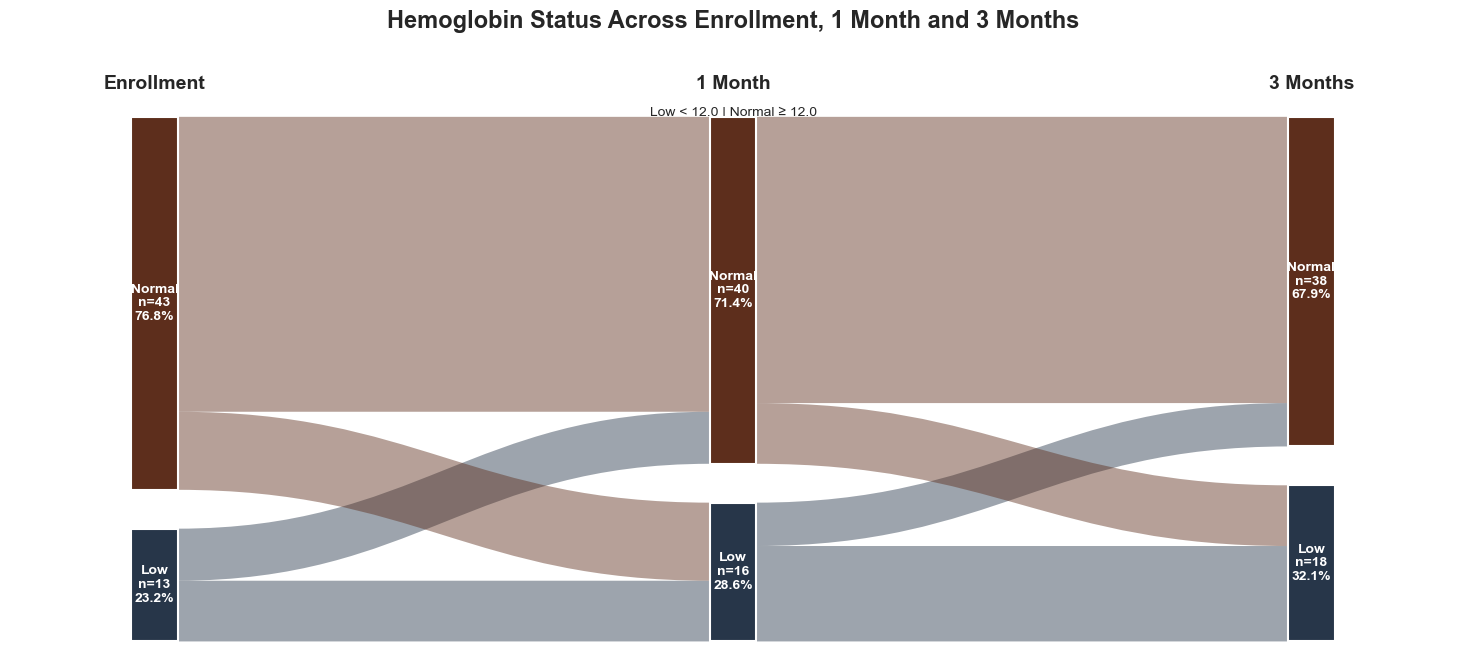


Serum Folate Status Across Enrollment, 1 Month and 3 Months
Participants included: 30
Cutoff used: 25.5


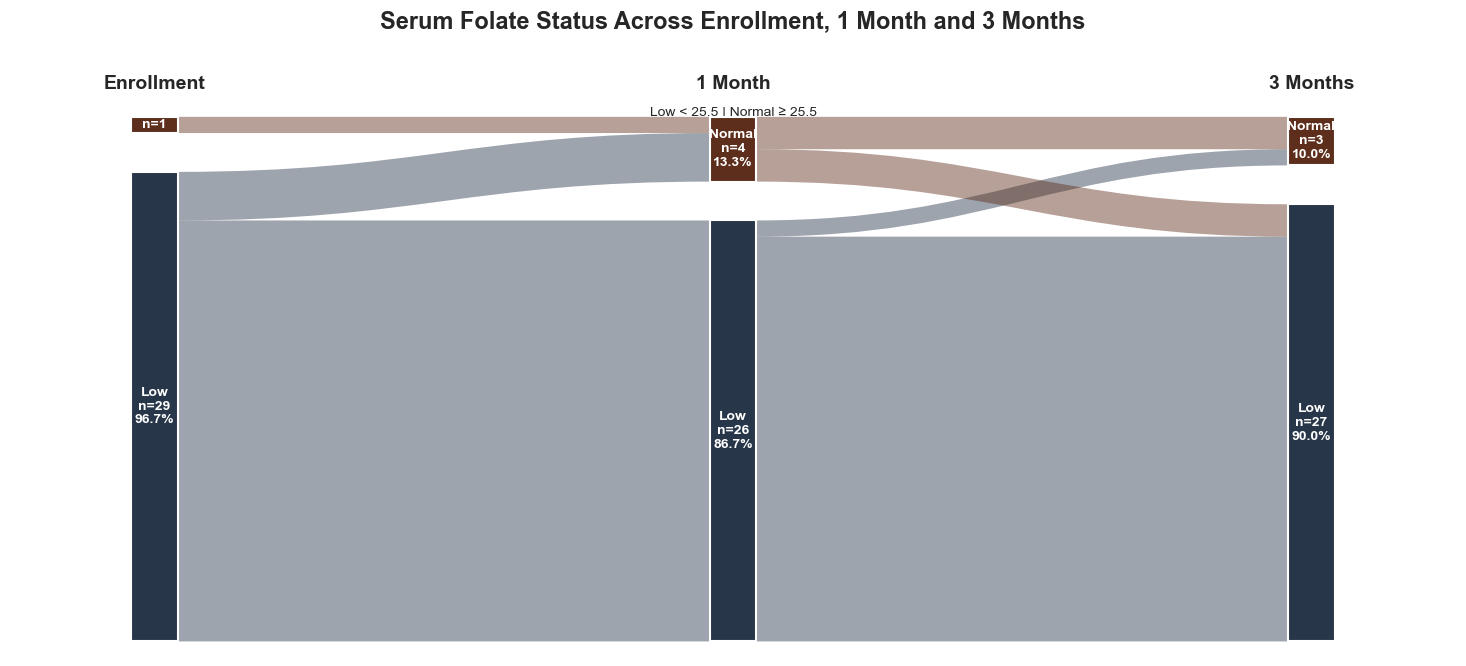


Red Blood Cell Folate Status Across Enrollment, 1 Month and 3 Months
Participants included: 30
Cutoff used: 400


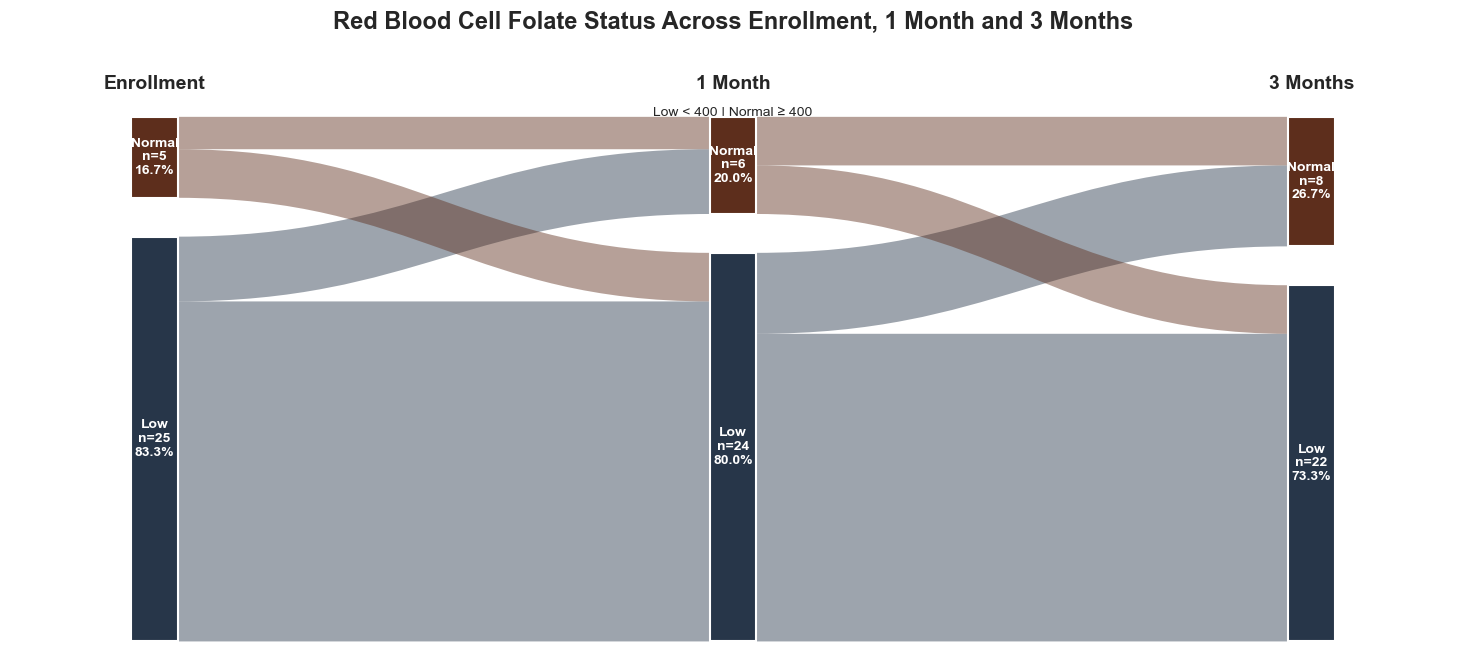

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.colors import to_hex
from pypalettes import load_cmap


# =========================================================
# 1. DEFINE VARIABLES AND CUTOFFS
# =========================================================

# ---------------------------------------------------------
# Hemoglobin
# ---------------------------------------------------------

hemoglobin_cols = [
    "hemog_Enrollment",
    "hemog_1_Month",
    "hemog_3_Month"
]

# IMPORTANT:
# Replace this with the cutoff specified in your study protocol.
hemoglobin_cutoff = 12.0


# ---------------------------------------------------------
# Serum folate
# ---------------------------------------------------------

serum_folate_cols = [
    "serum_folate_e_Enrollment",
    "serum_folate_1_Enrollment",
    "serum_folate_3_Enrollment"
]

# IMPORTANT:
# Replace this with the cutoff specified in your study protocol.
serum_folate_cutoff = 25.5


# ---------------------------------------------------------
# RBC folate
# ---------------------------------------------------------

rbc_folate_cols = [
    "rbc_folate_e_Enrollment",
    "rbc_folate_1_Enrollment",
    "rbc_folate_3_Enrollment"
]
rbc_folate_cutoff = 400


# =========================================================
# 2. LOAD PYPALLETES "X1"
# =========================================================

cmap = load_cmap("X1")

# Two consistent colours:
# Low = first side of palette
# Normal = opposite side of palette

status_colors = {
    "Low": to_hex(
        cmap(0.15),
        keep_alpha=False
    ),

    "Normal": to_hex(
        cmap(0.80),
        keep_alpha=False
    )
}

print("Colours used:")
print(status_colors)


# =========================================================
# 3. SEABORN STYLE
# =========================================================

sns.set_theme(
    style="white",
    context="talk"
)


# =========================================================
# 4. FUNCTION TO DRAW AN ALLUVIAL FLOW
# =========================================================

def draw_flow(
    ax,
    x0,
    x1,
    y0_bottom,
    y0_top,
    y1_bottom,
    y1_top,
    color,
    alpha=0.45
):
    """
    Draw one curved flow between two alluvial nodes.
    """

    control = 0.45

    verts = [
        (x0, y0_bottom),

        (
            x0 + control * (x1 - x0),
            y0_bottom
        ),

        (
            x1 - control * (x1 - x0),
            y1_bottom
        ),

        (x1, y1_bottom),

        (x1, y1_top),

        (
            x1 - control * (x1 - x0),
            y1_top
        ),

        (
            x0 + control * (x1 - x0),
            y0_top
        ),

        (x0, y0_top),

        (x0, y0_bottom)
    ]

    codes = [
        Path.MOVETO,
        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,
        Path.LINETO,
        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,
        Path.CLOSEPOLY
    ]

    path = Path(
        verts,
        codes
    )

    patch = PathPatch(
        path,
        facecolor=color,
        edgecolor="none",
        alpha=alpha
    )

    ax.add_patch(patch)


# =========================================================
# 5. FUNCTION TO CREATE COMPLETE ALLUVIAL PLOT
# =========================================================

def create_alluvial_plot(
    df,
    value_cols,
    cutoff,
    title,
    ylabel=None
):
    """
    Create an alluvial plot showing movement between
    Low and Normal categories at:

        Enrollment
        1 Month
        3 Months

    Parameters
    ----------
    df : pandas DataFrame
        Original dataset.

    value_cols : list
        Three columns representing Enrollment,
        1 Month and 3 Months.

    cutoff : float
        Clinical cutoff separating Low and Normal.

    title : str
        Plot title.

    ylabel : str, optional
        Name of laboratory measure.
    """

    # -----------------------------------------------------
    # Copy relevant data
    # -----------------------------------------------------

    df_plot = df[
        ["record_id"] + value_cols
    ].copy()


    # -----------------------------------------------------
    # Create category columns
    # -----------------------------------------------------

    category_cols = []

    for col in value_cols:

        category_col = col + "_category"

        category_cols.append(
            category_col
        )

        df_plot[category_col] = pd.Series(
            pd.NA,
            index=df_plot.index,
            dtype="string"
        )

        # Low
        df_plot.loc[
            df_plot[col].notna() &
            (df_plot[col] < cutoff),
            category_col
        ] = "Low"

        # Normal
        df_plot.loc[
            df_plot[col].notna() &
            (df_plot[col] >= cutoff),
            category_col
        ] = "Normal"


    # -----------------------------------------------------
    # Keep complete cases across all 3 time points
    # -----------------------------------------------------

    plot_data = (
        df_plot[
            ["record_id"] + category_cols
        ]
        .dropna(
            subset=category_cols
        )
        .copy()
    )

    total_n = len(plot_data)

    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)
    print(
        f"Participants included: {total_n}"
    )
    print(
        f"Cutoff used: {cutoff}"
    )


    # Stop if no complete participants
    if total_n == 0:

        print(
            "No participants have complete data "
            "at all three time points."
        )

        return


    # -----------------------------------------------------
    # Rename category columns
    # -----------------------------------------------------

    enrollment_col = category_cols[0]
    month1_col = category_cols[1]
    month3_col = category_cols[2]


    # -----------------------------------------------------
    # Counts by time point
    # -----------------------------------------------------

    plot_long = plot_data.melt(
        id_vars="record_id",

        value_vars=[
            enrollment_col,
            month1_col,
            month3_col
        ],

        var_name="timepoint",
        value_name="status"
    )


    timepoint_labels = {
        enrollment_col: "Enrollment",
        month1_col: "1 Month",
        month3_col: "3 Months"
    }


    plot_long["timepoint"] = (
        plot_long["timepoint"]
        .map(timepoint_labels)
    )


    # -----------------------------------------------------
    # Define ordering
    # -----------------------------------------------------

    timepoints = [
        "Enrollment",
        "1 Month",
        "3 Months"
    ]

    statuses = [
        "Low",
        "Normal"
    ]


    # -----------------------------------------------------
    # Calculate node counts
    # -----------------------------------------------------

    node_counts = (
        plot_long
        .groupby(
            [
                "timepoint",
                "status"
            ],
            observed=True
        )
        .size()
        .reset_index(
            name="count"
        )
    )


    # -----------------------------------------------------
    # Enrollment -> 1 Month transition
    # -----------------------------------------------------

    flow_1 = (
        plot_data
        .groupby(
            [
                enrollment_col,
                month1_col
            ],
            observed=True
        )
        .size()
        .reset_index(
            name="count"
        )
    )

    flow_1.columns = [
        "source_status",
        "target_status",
        "count"
    ]


    # -----------------------------------------------------
    # 1 Month -> 3 Months transition
    # -----------------------------------------------------

    flow_2 = (
        plot_data
        .groupby(
            [
                month1_col,
                month3_col
            ],
            observed=True
        )
        .size()
        .reset_index(
            name="count"
        )
    )

    flow_2.columns = [
        "source_status",
        "target_status",
        "count"
    ]


    # -----------------------------------------------------
    # X positions
    # -----------------------------------------------------

    x_positions = {
        "Enrollment": 0,
        "1 Month": 1,
        "3 Months": 2
    }


    # -----------------------------------------------------
    # Calculate node positions
    # -----------------------------------------------------

    gap = 0.08

    node_positions = {}


    for timepoint in timepoints:

        current_y = 0

        for status in statuses:

            count = node_counts.loc[
                (
                    node_counts["timepoint"]
                    == timepoint
                )
                &
                (
                    node_counts["status"]
                    == status
                ),
                "count"
            ]

            if len(count) > 0:

                count = int(
                    count.iloc[0]
                )

            else:

                count = 0


            height = count / total_n


            node_positions[
                (
                    timepoint,
                    status
                )
            ] = {

                "bottom":
                    current_y,

                "top":
                    current_y + height,

                "height":
                    height,

                "count":
                    count
            }


            current_y += (
                height + gap
            )


    # =====================================================
    # CREATE FIGURE
    # =====================================================

    fig, ax = plt.subplots(
        figsize=(15, 7)
    )


    # -----------------------------------------------------
    # Enrollment -> 1 Month offsets
    # -----------------------------------------------------

    source_offsets = {
        key: value["bottom"]
        for key, value
        in node_positions.items()
    }

    target_offsets = {
        key: value["bottom"]
        for key, value
        in node_positions.items()
    }


    # -----------------------------------------------------
    # Draw Enrollment -> 1 Month
    # -----------------------------------------------------

    for _, row in flow_1.iterrows():

        source_status = (
            row["source_status"]
        )

        target_status = (
            row["target_status"]
        )

        count = (
            row["count"]
        )

        flow_height = (
            count / total_n
        )


        source_key = (
            "Enrollment",
            source_status
        )

        target_key = (
            "1 Month",
            target_status
        )


        y0_bottom = (
            source_offsets[
                source_key
            ]
        )

        y0_top = (
            y0_bottom
            + flow_height
        )


        y1_bottom = (
            target_offsets[
                target_key
            ]
        )

        y1_top = (
            y1_bottom
            + flow_height
        )


        draw_flow(
            ax=ax,

            x0=(
                x_positions[
                    "Enrollment"
                ]
                + 0.04
            ),

            x1=(
                x_positions[
                    "1 Month"
                ]
                - 0.04
            ),

            y0_bottom=
                y0_bottom,

            y0_top=
                y0_top,

            y1_bottom=
                y1_bottom,

            y1_top=
                y1_top,

            color=
                status_colors[
                    source_status
                ],

            alpha=0.45
        )


        source_offsets[
            source_key
        ] += flow_height

        target_offsets[
            target_key
        ] += flow_height


    # -----------------------------------------------------
    # Reset offsets for second transition
    # -----------------------------------------------------

    source_offsets = {
        key: value["bottom"]
        for key, value
        in node_positions.items()
    }

    target_offsets = {
        key: value["bottom"]
        for key, value
        in node_positions.items()
    }


    # -----------------------------------------------------
    # Draw 1 Month -> 3 Months
    # -----------------------------------------------------

    for _, row in flow_2.iterrows():

        source_status = (
            row["source_status"]
        )

        target_status = (
            row["target_status"]
        )

        count = (
            row["count"]
        )

        flow_height = (
            count / total_n
        )


        source_key = (
            "1 Month",
            source_status
        )

        target_key = (
            "3 Months",
            target_status
        )


        y0_bottom = (
            source_offsets[
                source_key
            ]
        )

        y0_top = (
            y0_bottom
            + flow_height
        )


        y1_bottom = (
            target_offsets[
                target_key
            ]
        )

        y1_top = (
            y1_bottom
            + flow_height
        )


        draw_flow(
            ax=ax,

            x0=(
                x_positions[
                    "1 Month"
                ]
                + 0.04
            ),

            x1=(
                x_positions[
                    "3 Months"
                ]
                - 0.04
            ),

            y0_bottom=
                y0_bottom,

            y0_top=
                y0_top,

            y1_bottom=
                y1_bottom,

            y1_top=
                y1_top,

            color=
                status_colors[
                    source_status
                ],

            alpha=0.45
        )


        source_offsets[
            source_key
        ] += flow_height

        target_offsets[
            target_key
        ] += flow_height


    # =====================================================
    # DRAW NODE RECTANGLES
    # =====================================================

    node_width = 0.08


    for timepoint in timepoints:

        x = x_positions[
            timepoint
        ]

        for status in statuses:

            info = (
                node_positions[
                    (
                        timepoint,
                        status
                    )
                ]
            )


            rect = Rectangle(

                (
                    x
                    - node_width / 2,

                    info[
                        "bottom"
                    ]
                ),

                node_width,

                info[
                    "height"
                ],

                facecolor=
                    status_colors[
                        status
                    ],

                edgecolor="white",

                linewidth=1.5,

                zorder=5
            )


            ax.add_patch(
                rect
            )


            # ---------------------------------------------
            # Add node labels
            # ---------------------------------------------

            if info["height"] > 0:

                percentage = (
                    info["count"]
                    / total_n
                    * 100
                )


                ax.text(

                    x,

                    (
                        info["bottom"]
                        +
                        info["height"]
                        / 2
                    ),

                    (
                        f"{status}\n"
                        f"n={info['count']}\n"
                        f"{percentage:.1f}%"
                    ),

                    ha="center",

                    va="center",

                    fontsize=10,

                    color="white",

                    fontweight="bold",

                    zorder=6
                )


    # =====================================================
    # TIMEPOINT LABELS
    # =====================================================

    for timepoint, x in (
        x_positions.items()
    ):

        ax.text(

            x,

            1.13,

            timepoint,

            ha="center",

            va="bottom",

            fontsize=14,

            fontweight="bold"
        )


    # =====================================================
    # FORMATTING
    # =====================================================

    ax.set_xlim(
        -0.25,
        2.25
    )

    ax.set_ylim(
        -0.03,
        1.20
    )


    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        pad=22
    )


    # Optional subtitle with cutoff
    ax.text(
        1,
        1.075,
        f"Low < {cutoff} | Normal ≥ {cutoff}",
        ha="center",
        va="bottom",
        fontsize=10
    )


    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.set_xticks([])
    ax.set_yticks([])


    sns.despine(
        ax=ax,
        left=True,
        bottom=True
    )


    plt.tight_layout()

    plt.show()


    # -----------------------------------------------------
    # Return data used for plot if needed later
    # -----------------------------------------------------

    return {
        "data": plot_data,
        "node_counts": node_counts,
        "flow_1": flow_1,
        "flow_2": flow_2
    }


# =========================================================
# 6. PLOT 1 — HEMOGLOBIN
# =========================================================

hemoglobin_results = create_alluvial_plot(

    df=df,

    value_cols=hemoglobin_cols,

    cutoff=hemoglobin_cutoff,

    title=(
        "Hemoglobin Status Across "
        "Enrollment, 1 Month and 3 Months"
    )
)


# =========================================================
# 7. PLOT 2 — SERUM FOLATE
# =========================================================

serum_folate_results = create_alluvial_plot(

    df=df,

    value_cols=serum_folate_cols,

    cutoff=serum_folate_cutoff,

    title=(
        "Serum Folate Status Across "
        "Enrollment, 1 Month and 3 Months"
    )
)


# =========================================================
# 8. PLOT 3 — RBC FOLATE
# =========================================================

rbc_folate_results = create_alluvial_plot(

    df=df,

    value_cols=rbc_folate_cols,

    cutoff=rbc_folate_cutoff,

    title=(
        "Red Blood Cell Folate Status Across "
        "Enrollment, 1 Month and 3 Months"
    )
)


In [16]:
from io import BytesIO

# Results produced by the previous alluvial-plot cell
alluvial_outputs = [
    ("HB alluvial", hemoglobin_results),
    ("Serum folate", serum_folate_results),
    ("RBC alluvial", rbc_folate_results),
]


def create_alluvial_figure(results, title):
    """Recreate an alluvial plot from an alluvial results dictionary."""
    plot_data = results["data"].copy()
    node_counts = results["node_counts"].copy()
    flow_1 = results["flow_1"].copy()
    flow_2 = results["flow_2"].copy()

    timepoints = ["Enrollment", "1 Month", "3 Months"]
    statuses = ["Low", "Normal"]
    x_positions = dict(zip(timepoints, range(3)))
    total_n = len(plot_data)

    node_positions = {}

    for timepoint in timepoints:
        current_y = 0

        for status in statuses:
            count_row = node_counts[
                (node_counts["timepoint"] == timepoint)
                & (node_counts["status"] == status)
            ]

            count = int(count_row["count"].iloc[0]) if not count_row.empty else 0
            height = count / total_n

            node_positions[(timepoint, status)] = {
                "bottom": current_y,
                "top": current_y + height,
                "height": height,
                "count": count,
            }

            current_y += height + 0.08

    fig, ax = plt.subplots(figsize=(14, 7))

    def draw_transition(flow, source_timepoint, target_timepoint):
        source_offsets = {
            key: value["bottom"] for key, value in node_positions.items()
        }
        target_offsets = {
            key: value["bottom"] for key, value in node_positions.items()
        }

        for _, row in flow.iterrows():
            source_status = row["source_status"]
            target_status = row["target_status"]
            flow_height = row["count"] / total_n

            source_key = (source_timepoint, source_status)
            target_key = (target_timepoint, target_status)

            y0_bottom = source_offsets[source_key]
            y1_bottom = target_offsets[target_key]

            draw_flow(
                ax=ax,
                x0=x_positions[source_timepoint] + 0.04,
                x1=x_positions[target_timepoint] - 0.04,
                y0_bottom=y0_bottom,
                y0_top=y0_bottom + flow_height,
                y1_bottom=y1_bottom,
                y1_top=y1_bottom + flow_height,
                color=status_colors[source_status],
                alpha=0.45,
            )

            source_offsets[source_key] += flow_height
            target_offsets[target_key] += flow_height

    draw_transition(flow_1, "Enrollment", "1 Month")
    draw_transition(flow_2, "1 Month", "3 Months")

    for timepoint in timepoints:
        x = x_positions[timepoint]

        for status in statuses:
            info = node_positions[(timepoint, status)]

            ax.add_patch(
                Rectangle(
                    (x - 0.04, info["bottom"]),
                    0.08,
                    info["height"],
                    facecolor=status_colors[status],
                    edgecolor="white",
                    linewidth=1.5,
                    zorder=5,
                )
            )

            if info["height"] > 0:
                percentage = info["count"] / total_n * 100

                ax.text(
                    x,
                    info["bottom"] + info["height"] / 2,
                    f"{status}\nn={info['count']}\n{percentage:.1f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white",
                    fontweight="bold",
                    zorder=6,
                )

        ax.text(
            x,
            1.12,
            timepoint,
            ha="center",
            va="bottom",
            fontsize=13,
            fontweight="bold",
        )

    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_xlim(-0.25, 2.25)
    ax.set_ylim(-0.03, 1.2)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("off")

    plt.tight_layout()
    return fig


with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    workbook = writer.book

    # -----------------------------------------------------
    # Sheet 1: Demographic tables
    # -----------------------------------------------------
    demographic_sheet = "Demographic tables"

    demographic_output = tableone_df.copy()

    if isinstance(demographic_output.index, pd.MultiIndex):
        demographic_output = demographic_output.reset_index()
    else:
        demographic_output = demographic_output.reset_index()

    demographic_output.to_excel(
        writer,
        sheet_name=demographic_sheet,
        index=False,
        startrow=1,
    )

    worksheet = writer.sheets[demographic_sheet]
    worksheet.write(0, 0, "Demographic Table One Output")
    worksheet.set_column(0, 0, 45)
    worksheet.set_column(1, demographic_output.shape[1] - 1, 25)

    # -----------------------------------------------------
    # Sheets 2–4: Alluvial plots and transition data
    # -----------------------------------------------------
    for sheet_name, results in alluvial_outputs:
        worksheet = workbook.add_worksheet(sheet_name)
        writer.sheets[sheet_name] = worksheet

        title = {
            "HB alluvial": "Hemoglobin Status Transitions",
            "Serum folate": "Serum Folate Status Transitions",
            "RBC alluvial": "RBC Folate Status Transitions",
        }[sheet_name]

        worksheet.write(0, 0, title)

        # Insert the plot
        figure = create_alluvial_figure(results, title)
        image_data = BytesIO()
        figure.savefig(image_data, format="png", dpi=200, bbox_inches="tight")
        plt.close(figure)
        image_data.seek(0)

        worksheet.insert_image(
            "A2",
            "alluvial_plot.png",
            {"image_data": image_data, "x_scale": 0.8, "y_scale": 0.8},
        )

        # Export the data used to create the plot
        start_row = 40

        tables = [
            ("Participant data used in plot", results["data"]),
            ("Counts at each time point", results["node_counts"]),
            ("Enrollment to 1 Month transitions", results["flow_1"]),
            ("1 Month to 3 Months transitions", results["flow_2"]),
        ]

        for table_title, table in tables:
            worksheet.write(start_row, 0, table_title)
            table.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False,
                startrow=start_row + 1,
                startcol=0,
            )

            start_row += len(table) + 4

        worksheet.set_column("A:Z", 20)

print(f"Excel workbook exported to:\n{output_file}")

/opt/anaconda3/lib/python3.12/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/opt/anaconda3/lib/python3.12/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/opt/anaconda3/lib/python3.12/ast.py:587: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)
/opt/anaconda3/lib/python3.12/site-packages/executing/executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
/opt/anaconda3/lib/python3.12/ast.py:587: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)


NameError: name 'output_file' is not defined

In [ ]:


df[['Daily_consumption_month1_cat']].value_counts

TypeError: where() takes from 1 to 3 positional arguments but 4 were given

In [ ]:
df["Daily_consumption_month1_cat"] = np.where(
    df["Daily_consumption_month1"].isna(),
    np.nan,
    np.where(
        df["Daily_consumption_month1"] >= 5,
        "5+",
        "< 5"
    )
)

In [ ]:
df["Daily_consumption_month1_cat"]

0      < 5
1      < 5
2       5+
3       5+
4      < 5
      ... 
245     5+
246    < 5
247     5+
248    nan
249    nan
Name: Daily_consumption_month1_cat, Length: 250, dtype: object